In [69]:
from siphon.catalog import TDSCatalog

import time
from pyproj import Geod
from clisops.core import subset

import numpy as np
import xarray as xr
import geopandas as gpd

from xclim import atmos
from xclim.core.units import convert_units_to
import operator

In [29]:
# Ensemble de fonctions utilitaires pour la télémétrie du téléchargement du jeux de données
def timed_load(ds, label):
    t0  = time.perf_counter()
    ds = ds.load()
    dt  = time.perf_counter() - t0
    b   = ds.nbytes 
    mb  = b/1e6
    gb  = b/1e9
    print(f"{label:<28} {gb:8.1f} GB  {dt:6.1f} s  {mb/dt:6.1f} MB/s")
    return ds

def labelled_golfe_subset(ds):
    golfe_32198 = gpd.GeoDataFrame.from_file("/notebook_dir/writable-workspace/gulf_32198_bbox.geojson")
    bbox_ds = subset.subset_shape(ds, shape=golfe_32198)

    g = Geod(ellps="WGS84")
    lon, lat = bbox_ds.lon.values, bbox_ds.lat.values
    
    _, _, dx = g.inv(lon[:, :-1], lat[:, :-1], lon[:, 1:], lat[:, 1:])   # along rlon
    _, _, dy = g.inv(lon[:-1, :], lat[:-1, :], lon[1:, :], lat[1:, :])   # along rlat
    
    print("dlon: ", np.unique(np.diff(bbox_ds.rlon).round(3)), "dlat: ", np.unique(np.diff(bbox_ds.rlat).round(3)))
    for name, d in [("dx", dx), ("dy", dy)]:
        print(f"{name}: mean {d.mean()/1e3:.2f} km, min {d.min()/1e3:.2f}, max {d.max()/1e3:.2f}")
    return bbox_ds

In [72]:
# Accès au jeux de données - RCAS V3.2 · Daily · 1968-2024

url = "https://pavics.ouranos.ca/twitcher/ows/proxy/thredds/catalog/datasets/reanalyses/catalog.xml"  

# Create Catalog
cat = TDSCatalog(url)
cds = cat.datasets["day_NAM_GovCan_CaSR_v32_1968-2024.ncml"]
opendap_url = cds.access_urls["OPENDAP"]

# Extract needed variables only
# keep = {"sftof", "sfcWind", "winddir", "pr", "psl", "tas", "tasmax", "tasmin"} # whole set
keep = {"tas", "sfcWind", "winddir"} # Surface temperature only
all_vars = set(xr.open_dataset(opendap_url).data_vars)

ds = xr.open_dataset(opendap_url, chunks="auto",
                     drop_variables=list(all_vars - keep))

# Mask to Golfe bbox
golfe_ds = labelled_golfe_subset(ds)

# Load the data for the selected climatological period during winter months
clim_slice = bbox_ds.sel(time=slice("1990-09-01", "2020-09-01")) # lazy import
clim_slice = timed_load(clim_slice, "Golfe · 1991-2020 · Dec to Mar data") 
display(clim_slice)

dlon:  [0.09] dlat:  [0.09]
dx: mean 9.98 km, min 9.86, max 10.04
dy: mean 10.01 km, min 10.00, max 10.02
Golfe · 1991-2020 · Dec to Mar data      0.7 GB    59.3 s   695.9 MB/s


<xarray.Dataset> Size: 696MB
Dimensions:       (time: 10959, rlat: 115, rlon: 138)
Coordinates:
  * time          (time) datetime64[ns] 88kB 1990-09-01 ... 2020-09-01
  * rlat          (rlat) float32 460B -10.35 -10.26 -10.17 ... -0.27 -0.18 -0.09
  * rlon          (rlon) float32 552B 12.66 12.75 12.84 ... 24.81 24.9 24.99
    rotated_pole  int32 4B 1
    lat           (rlat, rlon) float32 63kB 46.18 46.16 46.13 ... 50.39 50.34
    lon           (rlat, rlon) float32 63kB -74.26 -74.13 ... -51.07 -50.95
Data variables:
    tas           (time, rlat, rlon) float32 696MB nan nan nan ... nan nan nan
Attributes: (12/30)
    Conventions:             CF-1.8
    Remarks:                 Original variable names are following the conven...
    contact:                 
    domain:                  NAM
    frequency:               day
    history:                 2025-12-16 11:21:02.543093: Created a copy of Ca...
    ...                      ...
    doi:                     https://doi.org/10.5194/hess-25-4917-2021
    description:             Original data source: https://hpfx.collab.scienc...
    institute:               Environment and Climate Change Canada
    institute_id:            ECCC
    dataset_description:     https://hpfx.collab.science.gc.ca/~scar700/rcas-...
    dataset_id:              CaSRv3.2

In [76]:
# Custom climatological reductions
YEARS_PER_DECADE = 10

def trend_per_decade(da: xr.DataArray) -> xr.DataArray:
    """Least-squares linear trend along time (one value per year), in input units per decade."""
    by_year = da.assign_coords(year=da.time.dt.year).swap_dims(time="year")
    slope = (by_year.polyfit("year", deg=1)                      # least squares: a₁·x + a₀
                .polyfit_coefficients.sel(degree=1, drop=True)   # slope a₁, per year
                .pipe(operator.mul, YEARS_PER_DECADE)            # per year → per decade
                .assign_attrs(units=f"{da.attrs['units']} / decade")) # units metadata
    
    r = xr.corr(by_year, by_year.year, dim="year")       # ignores NaN pairs
    n = by_year.count("year")                            # valid years per cell
    t = r * np.sqrt((n - 2) / (1 - r**2))
    p = xr.apply_ufunc(stats.t.sf, abs(t), n - 2) * 2
    return xr.Dataset({"slope": slope, "r2": r**2, "p": p}) 


In [77]:
# Monthly averages and trends

MONTH_START = "MS"

# --- Daily to monthly resample
# 1991-12-01 … 1991-12-31 | 1991-01-01 … 1991-01-28 | 1991-03-01 …
# └─ mean "1991-12-01"───┘  └─ mean "1991-01-01"───┘  └─ mean "1991-02-01" …
# -----

# Mean for each month, NaN assigned to months with no data
monthly = atmos.tg_mean(clim_slice["tas"], freq="MS").pipe(convert_units_to, "degC") # Output units converted to °C
djfm = monthly.sel(time=monthly.time.dt.month.isin([12, 1, 2, 3])) # Extraction of the DJFM monthly means

monthly_mean = djfm.groupby("time.month").mean()
monthly_trend = djfm.groupby("time.month").map(trend_per_decade) 

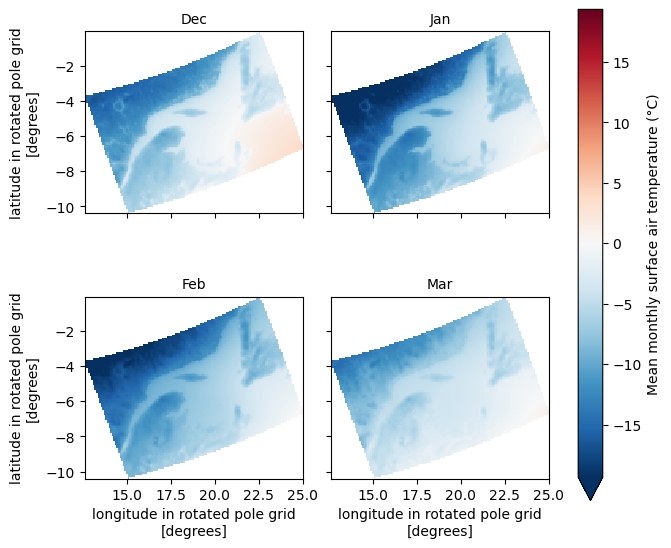

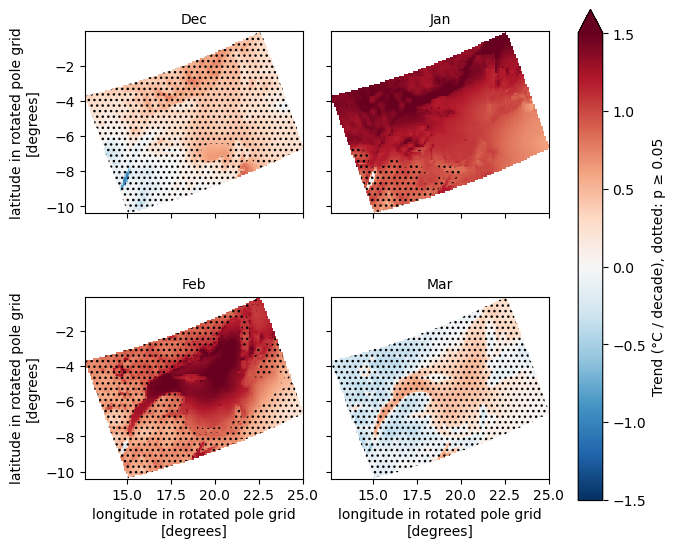

In [88]:
ALPHA = 0.05
NOT_SIGNIFICANT_HATCH = "..."

def winter_order(da):
    """Reorder month labels Dec→Mar and name them."""
    return da.sel(month=[12, 1, 2, 3]).assign_coords(month=["Dec", "Jan", "Feb", "Mar"])

def _hatch(ax, mask):
    ydim, xdim = mask.dims                      # same (y, x) order xarray uses for the facet
    ax.contourf(mask[xdim], mask[ydim], mask.astype(float),
                levels=[0.5, 1.5], colors="none", hatches=[NOT_SIGNIFICANT_HATCH])

def facet(da, label, hatch_mask=None, **plot_kw):
    da = winter_order(da)  # groupby order to Dec. -> Mar.
    if hatch_mask is not None:
        hatch_mask = winter_order(hatch_mask)
    kw = dict(cmap="RdBu_r", center=0, robust=True) | plot_kw
    fg = da.plot(col="month", col_wrap=2, cbar_kwargs={"label": label}, **kw)
    fg.set_titles("{value}")
    for ax, sel in zip(fg.axs.flat, fg.name_dicts.flat):
        ax.set_aspect("equal")
        if hatch_mask is not None and sel is not None:
            _hatch(ax, hatch_mask.sel(sel))
    return fg


a = facet(monthly_mean, "Mean monthly surface air temperature (°C)")
a = facet(monthly_trend.slope, f"Trend (°C / decade), dotted: p ≥ {ALPHA}", hatch_mask=monthly_trend.p >= ALPHA)



## Analyse de la validité des tendances - Températures atmosphérique de surface

L'affichage des valeurs de R² dans les panneaux mensuels supérieurs indique de plus grandes valeurs pour Janvier et Février, particulièrement sur l'étendue marine du Golfe et de l'Estuaire. Les panneaux de p value montrent des zones significatives de tendances au réchauffement pour le Golfe pour Janvier et Février, avec une petite zone de refroidissement dans l'estuaire supérieur Laurentien en Décembre. Aucune cellule de la grille ne possède un p value sous 0.05 pour le mois de Mars.